# Trabajo Práctico Especial: Fundamentos de la Ciencia de Datos
**Grupo 35** 
Integrantes: Rojas, Lucas Nahuel | Rodriguez Giacomasso, Santiago | Vailati, Nahuel

---
## 0. Importación de Librerías y Carga de Datos

Imports:
si falta algun import para tu codigo agregar abajo:

In [27]:
from wget import download
from os import path, listdir
import pandas as pd
# PARA AUMENTAR EL ANCHO PERMITIDO Y Q NO VEA DATOS CORTADOS
pd.set_option('display.max_colwidth', None)
# PARA DEVOLVER EL ANCHO X DEFAULT 
# pd.set_option('display.max_colwidth', 50)
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import requests

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
import seaborn as sns

from umap import UMAP

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

import statsmodels.api as sm



In [2]:
# Imports adicionales para las hipótesis 2 y 5 (pruebas estadísticas)
from scipy import stats
from scipy.stats import shapiro, kstest

Descarga/Lectura de dataframes:

In [3]:
if not path.exists("schema.csv"):
  download("https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2025/schema.csv")
if not path.exists("results.csv"):
  download("https://media.githubusercontent.com/media/StackExchange/Survey/6ae2209cd35a55e92739ba82f7887fb86807a069/packages/archive/2025/results.csv")

In [4]:
raw_dataset_results = pd.read_csv("results.csv")
raw_dataset_schema = pd.read_csv("schema.csv")

/tmp/ipykernel_341301/3656956904.py:1: DtypeWarning: Columns (56,74,92,97,98,105,109,110,132,162,165) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_dataset_results = pd.read_csv("results.csv")


---
## 1. Introducción: Origen y Naturaleza de los Datos

El conjunto de datos utilizado para este análisis proviene de la Encuesta de Desarrolladores 2025 (2025 Developer Survey) realizada por Stack Overflow, la cual se presenta como el informe definitivo sobre el estado del desarrollo de software a nivel global. En esta edición, la organización logró recopilar más de 49.000 respuestas de individuos pertenecientes a 177 países. 

El instrumento de recolección consistió en 62 preguntas enfocadas en relevar el uso de cientos de tecnologías diferentes, con un nuevo enfoque orientado a las herramientas de agentes de inteligencia artificial y Modelos de Lenguaje Grande (LLM). Según la publicación oficial, el objetivo primordial es proporcionar una instantánea sobre las necesidades de la comunidad, las tecnologías que utilizan y aquellas sobre las que desean aprender más.

Estructuralmente, los datos provistos se dividen en dos archivos complementarios: un esquema (`schema.csv`) que funciona como diccionario de las preguntas, y un archivo de resultados (`results.csv`). Debido a las limitaciones técnicas en la exportación de respuestas estructuradas en matrices (cuadrículas), las variables originales del esquema se encuentran fragmentadas en múltiples columnas independientes dentro del archivo de resultados.

**Organización del Trabajo (Limpieza en Capas):**
Para abordar un dataset de 172 columnas y casi 50.000 filas de manera robusta, organizamos el trabajo bajo el paradigma de "limpieza en capas". Primero, dividimos el universo de datos en subgrupos temáticos independientes. Sobre estos subgrupos aplicamos una limpieza estructural general. Luego, la "limpieza focalizada" (tratamiento de nulos o outliers específicos) se realizó bajo demanda dentro del análisis de cada hipótesis, utilizando exclusivamente las variables requeridas. Esto garantiza matrices completas para los modelos estadísticos sin sacrificar masivamente encuestas válidas por culpa de valores nulos en columnas irrelevantes.

---
## 2. Análisis exploratorio de los datos

### 2.1 Tipos de Variables y su Desglose en el Dataset de Resultados

Al cruzar la información provista por el esquema (raw_dataset_schema) con el archivo de respuestas (raw_dataset_results), es fundamental comprender la naturaleza estructural de cada tipo de pregunta (type), ya que esto define cómo se materializan los datos finales. A continuación, se detallan las distintas clasificaciones y su comportamiento en el dataset de resultados:   

- MC (Multiple Choice): Son preguntas de opción múltiple única o combinada. A diferencia de las matrices, su estructura no sufre alteraciones, por lo que se exportan como una única columna en el dataset de resultados con un conjunto limitado de respuestas posibles.   

- RO (Rank Over): Son preguntas de ordenamiento o jerarquización (ranking). Para almacenar el orden exacto que definió el usuario, el sistema genera una columna numérica nueva e independiente en los resultados por cada elemento o posición a rankear (por ejemplo, dividiéndose desde la opción 1 hasta la 15).   

- Matrix (Matrices de evaluación): Corresponden a cuadrículas bidimensionales (como escalas de Likert cruzadas con múltiples tecnologías). Dado que cada fila de un archivo CSV debe representar a un único encuestado, el sistema se ve obligado a desarmar estas matrices. Para lograrlo, toma el identificador base (el qname) y genera dinámicamente múltiples columnas independientes en los resultados, anexando el nombre de cada sub-opción evaluada al final.   

- TE (Text Entry): Corresponden a campos de texto de formato libre. Por lo general, se trasladan de forma directa y generan una única columna en el archivo de respuestas (frecuentemente identificadas con el sufijo _TEXT).   

- Variables Autogeneradas: Son columnas que no existen en el esquema original porque no corresponden a preguntas directas del cuestionario. Son generadas a posteriori por la propia plataforma para estandarizar respuestas y facilitar el análisis, como es el caso de ConvertedCompYearly, la cual convierte los salarios declarados a una única moneda continua (dólares anuales).  

### 2.2. Auditoría Estructural del Archivo

Al cargar el archivo de resultados, nos enfrentamos a un dataframe de gran dimensionalidad.

In [5]:
print(f"Total de observaciones (filas): {raw_dataset_results.shape[0]}")
print(f"Total de características (columnas): {raw_dataset_results.shape[1]}")
print("-" * 50)
print("Tipos de datos detectados:")
print(raw_dataset_results.dtypes.value_counts())
print("-" * 50)
raw_dataset_results.info()

Total de observaciones (filas): 49191
Total de características (columnas): 172
--------------------------------------------------
Tipos de datos detectados:
object     119
float64     52
int64        1
Name: count, dtype: int64
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49191 entries, 0 to 49190
Columns: 172 entries, ResponseId to JobSat
dtypes: float64(52), int64(1), object(119)
memory usage: 64.6+ MB


Al cargar el archivo de resultados, nos enfrentamos a un dataframe de 49.191 observaciones y 172 características. La abrumadora mayoría de las columnas se importaron como cadenas de texto (str), lo que indica una alta presencia de preguntas de opción múltiple y texto libre que requerirán codificación para su análisis matemático

### 2.3. Validación de Integridad (Replicación de Mercado)

Antes de proceder con la limpieza y el modelado estadístico, es fundamental auditar la veracidad del conjunto de datos crudo. Para ello, buscaremos replicar uno de los gráficos oficiales publicados en el reporte web de Stack Overflow correspondiente al sentimiento de los desarrolladores frente al uso de herramientas de IA (AISent):

![Gráfico oficial de Stack Overflow](grafico-de-barras-Oficial.png)

A diferencia de otras preguntas de opción múltiple con respuestas combinadas (como las de tipo Matrix, que se desglosan en múltiples sub-columnas en el archivo de resultados), AISent es de opción múltiple única (MC), por lo que el conteo es directo. Aislamos la columna, descartamos los valores nulos, y generamos la visualización.

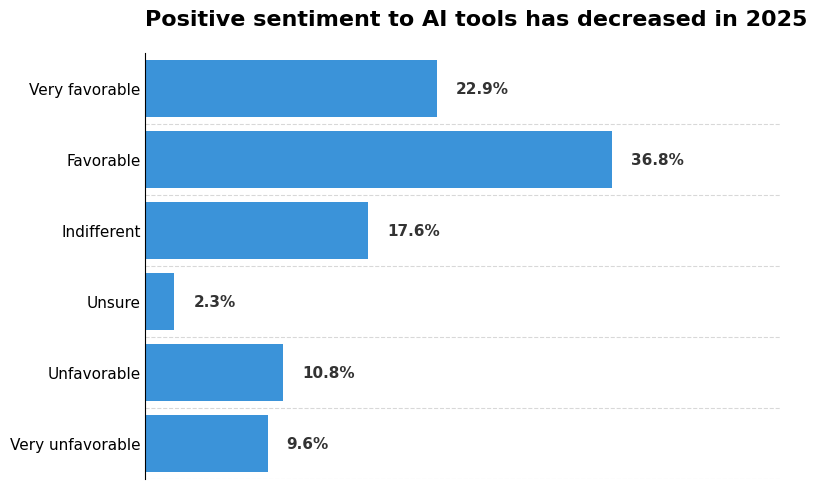

In [6]:

# 1. Aislamos la columna de sentimiento hacia la IA y eliminamos nulos
aisent_data = raw_dataset_results['AISent'].dropna()

# 2. Contamos las respuestas y calculamos el porcentaje sobre el total que respondió
aisent_counts = aisent_data.value_counts()
aisent_percentages = (aisent_counts / len(aisent_data)) * 100

# 3. Definimos el orden exacto de las categorías tal como aparece en la imagen oficial
orden_categorias = [
    "Very favorable",
    "Favorable",
    "Indifferent",
    "Unsure",
    "Unfavorable",
    "Very unfavorable"
]

# Reordenamos nuestra serie de porcentajes para que coincida con ese orden
aisent_percentages = aisent_percentages.reindex(orden_categorias)

# --- CONFIGURACIÓN DEL GRÁFICO ---
plt.figure(figsize=(8, 5))

# Usamos el color azul característico de Stack Overflow
color_so = '#2196F3'
ax = sns.barplot(x=aisent_percentages.values, y=aisent_percentages.index, color=color_so)

# Agregamos las etiquetas de porcentaje al final de cada barra
for p in ax.patches:
    width = p.get_width()
    plt.text(width + 1.5,                            # Posición X (margen a la derecha)
             p.get_y() + p.get_height() / 2,         # Posición Y (centrado vertical)
             f'{width:.1f}%',                        # Formato con 1 decimal
             ha='left', va='center', fontweight='bold', color='#333333', fontsize=11)

# Estética y títulos
plt.title('Positive sentiment to AI tools has decreased in 2025', 
          fontsize=16, fontweight='bold', loc='left', pad=20)
plt.xlabel('') 
plt.ylabel('') 
plt.xlim(0, 50) # Ajustamos el límite a 50% para que las barras ocupen el mismo espacio visual que en la imagen

# Ajustes de ejes para el estilo minimalista
plt.yticks(fontsize=11)
plt.xticks([]) # Ocultamos el eje X inferior

# Quitamos los bordes superior, derecho e inferior
sns.despine(bottom=True)
ax.tick_params(axis='y', length=0) # Ocultamos las marcas (rayitas) del eje Y

# Líneas punteadas horizontales tenues para separar las categorías (como en la imagen original)
for y in range(len(orden_categorias)):
    ax.axhline(y=y + 0.5, color='gray', linestyle='--', alpha=0.3, linewidth=0.8)

plt.tight_layout()
plt.show()

Al comparar nuestra visualización con el reporte oficial de Stack Overflow, observamos que los resultados obtenidos son idénticos al del reporte oficial. Las proporciones y el ranking de favorabilidad se replican de manera exacta (por ejemplo, el sentimiento "Favorable" lidera con un 36.8%, seguido del "Very Favorable" con 22.9%).

Esta prueba empírica confirma que los datos cargados localmente coinciden al 100% con los de la organización matriz, validando la integridad técnica del dataset para continuar con la partición en subgrupos, la limpieza en capas y el análisis de las hipótesis.

### 2.4. Estrategia de Subgrupos y Limpieza Estructural (Limpieza en Capas)


Para comenzar con la limpieza en capas. Primero, dividimos el universo de datos en 4 subgrupos temáticos independientes:
1. Perfil Económico y Demográfico: 

    Contiene las variables para cruzar el país de origen con la experiencia y los ingresos, permitiendo limpiar las hipótesis de mercado laboral básico.

    Columnas: Country, WorkExp, ConvertedCompYearly, CompTotal, Currency, Age, EdLevel, Employment, YearsCode.



2. IA, Experiencia y Satisfacción General (Impacto de la IA): 

    Agrupa la adopción de herramientas de inteligencia artificial con los años en la industria y el nivel de satisfacción general, sin mezclar matrices complejas.

    Columnas: WorkExp, AIAcc, JobSat, AISent, AISelect, AIThreat, AILearnHow.



3. Retención y Motores de Satisfacción (Cambio de Rol):

    Aísla exclusivamente el ecosistema de la matriz de satisfacción y la intención de cambio laboral. 

    Columnas: NewRole, JobSatPoints_1 hasta JobSatPoints_15, JobSatPoints_15_TEXT, JobSat.



4. Valor de Mercado y Entorno Organizacional (Premio Salarial): 

    Agrupa los factores corporativos y tecnológicos que determinan el sueldo de un desarrollador.

    Columnas: ConvertedCompYearly, WorkExp, OrgSize, AISelect, RemoteWork, DevType, Industry, ICorPM.

In [7]:
# 1. Definición de las listas de columnas para cada subgrupo
cols_g1 = ['Country', 'WorkExp', 'ConvertedCompYearly', 'CompTotal', 'Currency', 'Age', 'EdLevel', 'Employment', 'YearsCode']
cols_g2 = ['WorkExp', 'AIAcc', 'JobSat', 'AISent', 'AISelect', 'AIThreat', 'AILearnHow']

# Para el Grupo 3 extraemos dinámicamente todas las de JobSatPoints (del 1 al 15 + TEXT) para evitar hardcodearlas
cols_jobsat = [col for col in raw_dataset_results.columns if col.startswith('JobSatPoints')]
cols_g3 = ['NewRole', 'JobSat'] + cols_jobsat

cols_g4 = ['ConvertedCompYearly', 'WorkExp', 'OrgSize', 'AISelect', 'RemoteWork', 'DevType', 'Industry', 'ICorPM']


# 2. Creación de los DataFrames independientes para cada subgrupo

# Subgrupo 1: Perfil Económico (Para Hipótesis A y HU1)
df_perfil_economico = raw_dataset_results[cols_g1].copy()

# Subgrupo 2: Impacto de la IA (Para Hipótesis B y HB1)
df_impacto_ia = raw_dataset_results[cols_g2].copy()

# Subgrupo 3: Cambio de Rol (Para Hipótesis C)
df_cambio_rol = raw_dataset_results[cols_g3].copy()

# Subgrupo 4: Premio Salarial (Para Hipótesis M4)
df_premio_salarial = raw_dataset_results[cols_g4].copy()



A continuacion analizaremos uno por uno estos subgrupos y que decisiones tomamos para hacerles una limpieza general.

#### 2.4.1. Subgrupo 1: Perfil Económico y Demográfico
No se realizo ninguna limpieza a nivel general del Subgrupo 1, dentro de las distintas hipotesis que lo utilizaban se realizaron filtros y limpiezas de acuerdo a las necesidades.

#### 2.4.2. Subgrupo 2: IA, Experiencia y Satisfacción General (Impacto de la IA)

Limpieza general del Subgrupo 2 (`df_impacto_ia`). Trabajamos sobre una copia (`df_impacto_ia_limpio`) para no modificar el subgrupo original. Las acciones aplicadas son:

- **`WorkExp`:** los valores de 99 años o más pasan a nulo (la fila se conserva).
- **`JobSat`:** se verifica que todos los valores estén en el rango válido de 0 a 10.
- **Nulos:** no se imputan; cada hipótesis elimina solo las filas con nulo en sus dos variables.

La codificación ordinal de `AIAcc` y `AISent` es propia de cada hipótesis y se explica en 3.2.3 y 3.5.3.

In [8]:
# 1. Trabajamos sobre una copia del subgrupo 2
df_impacto_ia_limpio = df_impacto_ia.copy()

# 2. Estado de los nulos antes de limpiar
nulos_g2 = df_impacto_ia_limpio.isna().sum()
print(pd.DataFrame({"nulos": nulos_g2, "% nulos": (nulos_g2 / len(df_impacto_ia_limpio) * 100).round(1)}))

# 3. WorkExp: valores imposibles (99 o más años) pasan a nulo; la fila se conserva
umbral_experiencia_g2 = 99
print("\nWorkExp pasados a nulo:", (df_impacto_ia_limpio["WorkExp"] >= umbral_experiencia_g2).sum())
df_impacto_ia_limpio.loc[df_impacto_ia_limpio["WorkExp"] >= umbral_experiencia_g2, "WorkExp"] = np.nan

# 4. JobSat: chequeo del rango válido (0 a 10)
print("JobSat fuera de 0-10:", ((df_impacto_ia_limpio["JobSat"] < 0) | (df_impacto_ia_limpio["JobSat"] > 10)).sum())

            nulos  % nulos
WorkExp      6298     12.8
AIAcc       15894     32.3
JobSat      22521     45.8
AISent      15724     32.0
AISelect    15471     31.5
AIThreat    13113     26.7
AILearnHow  20934     42.6

WorkExp pasados a nulo: 39
JobSat fuera de 0-10: 0


Justificación de limpieza para el informe:

- **Valores imposibles en `WorkExp`:** hay un pico aislado en 99 y 100 años de experiencia (incluso en personas de 18 a 24 años), lo que indica errores de carga o respuestas de relleno. Se pasan a nulo y **no se elimina la fila**, para conservar las respuestas de esa persona en las demás preguntas. Los valores entre 58 y 88 años son pocos y ambiguos: se dejan y se declaran como limitación. El Subgrupo 4 usa un umbral más estricto (más de 60 años, ver 2.4.4) porque su modelo de regresión es más sensible a valores extremos.
- **Rechazo a la imputación de datos:** son encuestas de opinión con preguntas condicionales; no podemos saber si un nulo es "no respondió" o "la pregunta no le apareció". Rellenar con promedios o medianas introduciría un sesgo artificial y distorsionaría la varianza real. `JobSat` tiene casi la mitad de nulos, probablemente porque la pregunta no se mostró a quienes no trabajan (es una hipótesis: el esquema no lo documenta).
- **Eliminación por subconjunto:** un `dropna()` global sobre las 172 columnas eliminaría casi todas las filas por las columnas de texto libre con muy alta tasa de nulos. Primero se aíslan las variables de cada hipótesis y recién entonces se descartan las filas incompletas.
- **Valores bajos de `JobSat` (0, 1 y 2):** son personas muy insatisfechas, respuestas reales dentro de la escala; no son outliers a eliminar.

#### 2.4.3. Subgrupo 3: Retención y Motores de Satisfacción (Cambio de Rol)

Transformaciones sobre Subgrupo 3: Filtrado de filas que no responderion la pregunta de rankear atributos por satisfaccion generada:

In [9]:
# 1. Identificamos estrictamente las 15 columnas numéricas de ranking
cols_jobsat_numericas = [
    col for col in df_cambio_rol.columns 
    if col.startswith('JobSatPoints') and not col.endswith('TEXT')
]

# 2. Limpieza general del subgrupo: eliminamos filas de usuarios que no completaron el ranking
df_subgrupo_satisfaccion_limpio = df_cambio_rol.dropna(subset=cols_jobsat_numericas).copy()


#### 2.4.4. Subgrupo 4: Valor de Mercado y Entorno Organizacional (Premio Salarial)

Se aplicó una limpieza estructural sobre el Subgrupo 4:
- Borramos filas con valores nulos en ConvertedCompYearly
- Filtro lógico inferior de ingresos (ConvertedCompYearly): piso conservador de 1000 USD anuales.
- Filtro lógico de valores atípicos (WorkExp): Umbral maximo de 60 años, los que lo superan los borramos.

In [10]:
df_premio_salarial_limpio = df_premio_salarial.dropna(subset=['ConvertedCompYearly']).copy()

umbral_salario_min = 1000 # USD anuales (ver si ajustar a otros valores)
df_premio_salarial_limpio = df_premio_salarial_limpio[df_premio_salarial_limpio['ConvertedCompYearly'] >= umbral_salario_min].copy()

umbral_experiencia = 60
df_premio_salarial_limpio.loc[df_premio_salarial_limpio['WorkExp'] > umbral_experiencia, 'WorkExp'] = np.nan

df_premio_salarial_limpio = df_premio_salarial_limpio.dropna(subset=['WorkExp']).copy()

print(f"Total de observaciones tras la limpieza general del Subgrupo 4: {len(df_premio_salarial_limpio)}")

Total de observaciones tras la limpieza general del Subgrupo 4: 22804


---
## 3. Hipótesis y resolución

### 3.1. Hipótesis 1: Seniority de los Encuestados en Argentina.

#### 3.1.1: Definición y Motivación

**Hipotesis:** Mas del 50% de los encuestados argentinos tiene < 3 años de experiencia, que es el umbral para posiciones mid-level (umbral de concenso generalizado obtenido por Gemini cruzando Matrices públicas de las Grandes Tecnológicas (Big Tech), Ofertas de empleo y datos de portales de reclutamiento (Aggregated Job Boards) y Repositorios de Código Abierto sobre Progresión Profesional)

**Motivación:** Evaluar la representatividad de la muestra local frente a la denominada «crisis de contratación junior» en el sector tecnológico. Determinar si los datos reflejan un predominio de perfiles iniciales en Argentina o si, por el contrario, la comunidad encuestada se compone mayoritariamente de profesionales consolidados.

#### 3.1.2: Estrategia de abordaje y Acondicionamiento

Para evaluar esta hipótesis, se procedió de la siguiente manera:
1. **Filtrado geográfico:** Se aisló el subconjunto de encuestados cuyo país de residencia es Argentina.

In [11]:
encuestados_argentina_hipotesis1 = df_perfil_economico[df_perfil_economico["Country"]=="Argentina"].copy()

2. **Análisis y tratamiento de nulos:** Se analizó la columna `WorkExp` en dichos registros. En los casos donde el valor de experiencia era nulo, se examinó la información complementaria del perfil, identificando que una gran mayoría correspondía a estudiantes o personas sin empleo previo, por lo que se procedió a reasignar dichos valores nulos a 0 años de experiencia de forma justificada.

In [12]:
# Vemos si hay valores nulos
encuestados_argentina_hipotesis1[["WorkExp"]].info()

<class 'pandas.core.frame.DataFrame'>
Index: 222 entries, 88 to 48790
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   WorkExp  200 non-null    float64
dtypes: float64(1)
memory usage: 3.5 KB


In [13]:
# Podemos observar que de 222 entradas, 200 son no nulas
filas_nulos = encuestados_argentina_hipotesis1[encuestados_argentina_hipotesis1["WorkExp"].isna()]
filas_nulos

,Country,WorkExp,ConvertedCompYearly,CompTotal,Currency,Age,EdLevel,Employment,YearsCode
1329,Argentina,NaN,NaN,NaN,ARS\tArgentine peso,25-34 years old,Some college/university study without earning a degree,Not employed,6.0
6761,Argentina,NaN,NaN,NaN,ARS\tArgentine peso,18-24 years old,Some college/university study without earning a degree,Student,5.0
6762,Argentina,NaN,NaN,NaN,ARS\tArgentine peso,18-24 years old,"Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)",Student,7.0
9232,Argentina,NaN,NaN,NaN,ARS\tArgentine peso,18-24 years old,Some college/university study without earning a degree,Student,1.0
10240,Argentina,NaN,NaN,0.0,ARS\tArgentine peso,18-24 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Student,6.0
11464,Argentina,NaN,NaN,NaN,USD United States dollar,25-34 years old,Some college/university study without earning a degree,Not employed,10.0
12329,Argentina,NaN,NaN,NaN,ARS\tArgentine peso,25-34 years old,Some college/university study without earning a degree,Student,8.0
13592,Argentina,NaN,NaN,NaN,ARS\tArgentine peso,18-24 years old,Some college/university study without earning a degree,Employed,2.0
13743,Argentina,NaN,NaN,NaN,ARS\tArgentine peso,18-24 years old,"Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)",Student,2.0
14019,Argentina,NaN,NaN,NaN,ARS\tArgentine peso,25-34 years old,Some college/university study without earning a degree,Student,2.0


In [14]:
# Podemos observar que quienes no respondieron a la pregunta sobre los años de experiencia trabajando, son de perfiles distintos
filas_nulos["Employment"].unique()

array(['Not employed', 'Student', 'Employed',
       'Independent contractor, freelancer, or self-employed'],
      dtype=object)

In [15]:
# Ya que la mayoria son estudiantes o no empleados, procedemos a colocarles los años de experiencia en 0
encuestados_argentina_hipotesis1["WorkExp"] = encuestados_argentina_hipotesis1["WorkExp"].fillna(0)

3. **Construcción de la métrica:** Se agrupó la experiencia en dos categorías (< 3 años y $\ge$ 3 años) para calcular las proporciones exactas mediante un gráfico circular (torta).

In [21]:
experiencia_encuestados_argentina = encuestados_argentina_hipotesis1["WorkExp"]
supera = (experiencia_encuestados_argentina >= 3.0).sum()
no_supera = (experiencia_encuestados_argentina < 3.0).sum()

#### 3.1.3: Resultados obtenidos y discusión

A partir del procesamiento de los datos filtrados, se obtuvo la distribución porcentual del *seniority* de los desarrolladores argentinos. 

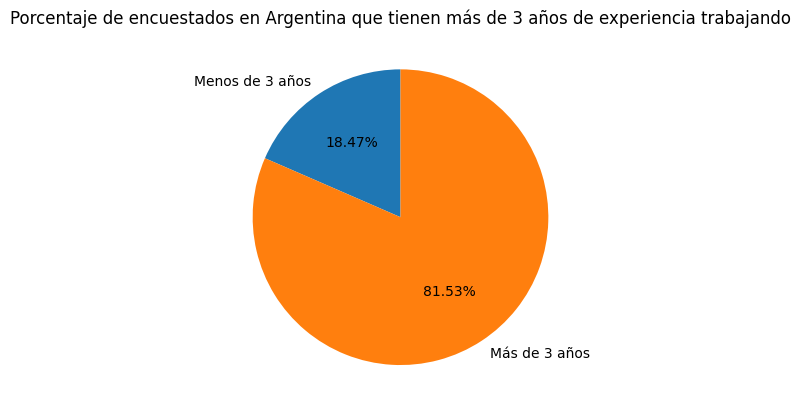

In [22]:
plt.pie(
    [no_supera, supera],
    labels=["Menos de 3 años", "Más de 3 años"],
    autopct="%1.2f%%",
    startangle=90,
)
plt.title("Porcentaje de encuestados en Argentina que tienen más de 3 años de experiencia trabajando")
plt.show()

**Figura X.** Distribución porcentual de los encuestados en Argentina según su experiencia laboral (umbral de 3 años).

Los resultados cuantitativos indicaron que la gran mayoría de los encuestados argentinos supera el umbral de los 3 años de experiencia, desacoplando la muestra local de la percepción de mercado masivo junior.

### 3.2. Hipótesis 2: Satisfacción Laboral y Postura hacia la IA

#### 3.2.1: Definición y Motivación

Hipotesis Bivariada Planteada:


La satisfacción laboral de los desarrolladores se relaciona con su postura frente al uso de herramientas de Inteligencia Artificial.

Es una hipótesis bivariada propia del grupo: Necesitamos de una variable numérica (`JobSat`, satisfacción en una escala de 0 a 10) y una ordinal (`AISent`, postura hacia la IA en cinco niveles, de "Very unfavorable" a "Very favorable").

Motivación:


Analizar si existe una asociación entre la percepción de la IA y el bienestar laboral, aportando información útil para comprender cómo la incorporación de estas herramientas puede relacionarse con el clima organizacional de los equipos.

Planteo estadístico:

- **H0:** la satisfacción laboral es la misma en los cinco niveles de postura. 
- **H1:** en al menos un nivel es distinta. Nivel de significación: alfa = 0,05. Una encuesta es observacional: se evalúa **asociación**, no causalidad.

#### 3.2.2: Estrategia de abordaje y Acondicionamiento

Para validar esta hipótesis utilizaremos el Subgrupo 2 limpio (`df_impacto_ia_limpio`, ver 2.4.2):

Variable 1 (`JobSat`): numérica discreta de 0 a 10. Es asimétrica hacia la izquierda: la mayoría responde entre 7 y 9.

Variable 2 (`AISent`): categórica ordinal (MC) de cinco niveles.

Exclusión de variables no necesarias: las demás columnas del subgrupo (`WorkExp`, `AIAcc`, `AISelect`, `AIThreat`, `AILearnHow`) no intervienen en esta hipótesis.

No se imputan los nulos: `JobSat` tiene casi la mitad de nulos (posiblemente por preguntas condicionales) y `AISent` cerca de un tercio. Rellenarlos introduciría un sesgo artificial en una encuesta de opinión. Como el análisis se hace sobre dos columnas, el `dropna` se aplica solo sobre ellas y no sobre las 172 columnas del dataset.

El abordaje sigue el flujo: análisis gráfico, verificación de normalidad y homocedasticidad, y elección de la prueba.

In [ ]:
# Aislamos las dos variables de la hipótesis y eliminamos las filas con nulos en alguna de ellas (sin imputar)
df_hipotesis_hb1 = df_impacto_ia_limpio[["JobSat", "AISent"]].dropna().copy()

print(f"Observaciones con JobSat y AISent respondidas: {len(df_hipotesis_hb1)} (sobre {len(df_impacto_ia_limpio)} filas)")

#### 3.2.3: Transformaciones e Ingeniería de Características

`AISent` es ordinal y las pruebas necesitan números. Asignamos 1 a 5 con un diccionario y `.map`. El orden se define a mano: si lo dejáramos a pandas, ordenaría alfabéticamente. La respuesta **"Unsure"** ("no sé") no es un punto de la escala, así que no se incluye en el diccionario y `.map` la convierte en nulo; después se eliminan esas filas. `JobSat` no requiere transformaciones.

In [ ]:
orden_aisent = {"Very unfavorable": 1, "Unfavorable": 2, "Indifferent": 3,
                "Favorable": 4, "Very favorable": 5}

df_hipotesis_hb1["AISent_num"] = df_hipotesis_hb1["AISent"].map(orden_aisent)

# Control: respuestas sin código (solo debería aparecer "Unsure")
print(df_hipotesis_hb1[df_hipotesis_hb1["AISent_num"].isna()]["AISent"].value_counts())

# Excluimos "Unsure" de esta hipótesis
df_hipotesis_hb1 = df_hipotesis_hb1.dropna(subset=["AISent_num"]).copy()
print(f"Total de observaciones listas para el análisis: {len(df_hipotesis_hb1)}")

El control debe mostrar solo `Unsure`. Si aparece otra categoría, hay un texto mal escrito en el diccionario y esa respuesta se estaría perdiendo.

#### 3.2.4: Modelado y Exploración Analítica

##### 3.2.4.1 Análisis gráfico

Antes de aplicar las pruebas miramos los datos. Graficamos la satisfacción laboral de cada nivel de AISent con un boxplot con muesca (`notch=True`): la caja es el 50% central, la línea es la mediana y la muesca es una zona de incertidumbre de la mediana. Si las muescas de dos cajas no se superponen, las medianas probablemente difieren. Es una pista visual, **no una prueba**. Además, el histograma de JobSat muestra su forma y su asimetría (`skew`).

In [ ]:
print("Personas por nivel de AISent:")
print(df_hipotesis_hb1["AISent_num"].value_counts().sort_index())
print("\nMediana de JobSat por nivel de AISent:")
print(df_hipotesis_hb1.groupby("AISent_num")["JobSat"].median())

plt.figure(figsize=(8, 4.5))
sns.boxplot(x="AISent_num", y="JobSat", data=df_hipotesis_hb1, notch=True)
plt.xlabel("AISent (1 = muy desfavorable, 5 = muy favorable)")
plt.ylabel("JobSat (0-10)")
plt.title("Satisfacción laboral según postura hacia la IA")
plt.show()

In [ ]:
sns.histplot(df_hipotesis_hb1["JobSat"], bins=11, discrete=True)
plt.title("Distribución de JobSat")
plt.show()
print("Asimetría (skew) de JobSat:", round(df_hipotesis_hb1["JobSat"].skew(), 2))

`JobSat` toma solo 11 valores enteros y es asimétrica hacia la izquierda. Como es discreta, la mediana y el cuartil superior pueden coincidir y el boxplot se ve plano en algunos grupos: no es un error del gráfico. Los puntos sueltos en 0, 1 y 2 son personas muy insatisfechas; son respuestas reales y no se eliminan.

##### 3.2.4.2 Normalidad (Shapiro-Wilk, Kolmogorov-Smirnov y QQ plot)

Para elegir entre una prueba paramétrica (ANOVA) y una no paramétrica hay que ver si JobSat es normal **dentro de cada grupo**. La H0 de normalidad dice que los datos siguen una distribución normal: si el p-valor es menor a 0,05 se rechaza. Kolmogorov-Smirnov se aplica sobre los datos estandarizados (se resta la media y se divide por el desvío). Con grupos de más de 5.000 observaciones `scipy` avisa que el p-valor de Shapiro es aproximado; es esperable.

In [ ]:
grupos_hb1 = [g["JobSat"] for _, g in df_hipotesis_hb1.groupby("AISent_num")]

for i, g in enumerate(grupos_hb1, start=1):
    estadistico, p_valor = shapiro(g)
    print(f"AISent = {i}: Shapiro-Wilk Estadístico={estadistico:.3f}, p-valor={p_valor:.3g}")

for i, g in enumerate(grupos_hb1, start=1):
    estadistico, p_valor = kstest((g - g.mean()) / g.std(), 'norm')
    print(f"AISent = {i}: Kolmogorov-Smirnov Estadístico={estadistico:.3f}, p-valor={p_valor:.3g}")

In [ ]:
fig, ejes = plt.subplots(1, 5, figsize=(18, 3.5))
for i, g in enumerate(grupos_hb1):
    stats.probplot(g, dist="norm", plot=ejes[i])
    ejes[i].set_title(f"QQ plot AISent = {i + 1}")
plt.tight_layout()
plt.show()

Los datos evaluados no siguen una distribución normal, una conclusión que se sostiene al cruzar el análisis estadístico con el diagnóstico visual:

- Evidencia analítica (Test de Hipótesis): Las pruebas de Shapiro-Wilk y Kolmogorov-Smirnov parten de la hipótesis nula ($H_0$) de que la muestra proviene de una distribución normal. Al obtener p-valores infinitesimales (en el orden de e-34 a e-263, todos estrictamente menores al nivel de significancia $\alpha = 0.05$), se rechaza categóricamente esta premisa para todos los grupos.

- Evidencia visual (QQ Plots): Para asumir normalidad, los cuantiles de la muestra (puntos azules) deberían alinearse estrechamente sobre la recta diagonal roja. Observamos que la distribución se desvía drásticamente y forma un patrón escalonado. Estas franjas horizontales revelan que los datos son marcadamente discretos, violando la naturaleza continua que exige teóricamente una campana de Gauss.

##### 3.2.4.3 Homocedasticidad (Levene)

H0: las varianzas de los cinco grupos son **iguales**. Si p < 0,05 se rechaza y las varianzas son distintas.

In [ ]:
estadistico_lev, p_lev = stats.levene(*grupos_hb1)
print(f"Test de Levene para JobSat: Estadístico={estadistico_lev:.3f}, p-valor={p_lev:.3g}")

alfa = 0.05
if p_lev > alfa:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("Las varianzas de JobSat son iguales entre los grupos de AISent.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Las varianzas de JobSat son diferentes entre los grupos de AISent.")

##### 3.2.4.4 Prueba de hipótesis: Kruskal-Wallis

Hay **cinco grupos independientes** (cada persona está en un solo nivel de AISent) y JobSat no es normal. Por eso usamos **Kruskal-Wallis**, la alternativa no paramétrica al ANOVA para comparar más de dos grupos. Es la generalización de Mann-Whitney U (que compara solo dos). Solo indica **si hay diferencia** en algún grupo, no entre cuáles ni en qué sentido.

- **H0:** JobSat tiene la misma distribución en los cinco niveles de AISent.
- **H1:** en al menos un nivel es distinta. Nivel de significación: alfa = 0,05.

In [ ]:
estadistico_kw, p_kw = stats.kruskal(*grupos_hb1)
print(f"Test de Kruskal-Wallis para JobSat: Estadístico={estadistico_kw:.3f}, p-valor={p_kw:.3g}")

alfa = 0.05
if p_kw > alfa:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en JobSat entre los niveles de AISent.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en JobSat entre los niveles de AISent.")

##### 3.2.4.5 Sentido de la asociación: correlación de Spearman

Kruskal-Wallis no dice en qué sentido va la relación. Para eso calculamos la correlación de Spearman entre JobSat y AISent_num. Trabaja con rangos (el orden de los valores), por lo que sirve para una variable ordinal y no exige normalidad. Va de -1 a 1: positiva significa que a una postura más favorable hacia la IA le corresponde más satisfacción, y negativa que le corresponde menos; cercana a 0 significa que no hay asociación.

In [ ]:
tabla_corr = df_hipotesis_hb1[["JobSat", "AISent_num"]].corr(method="spearman")
rho = tabla_corr.loc["JobSat", "AISent_num"]
print(tabla_corr)
print(f"\nCorrelación de Spearman = {rho:.3f}")

#### 3.2.5: Resultados obtenidos y discusión

##### 3.2.5.1 Hipótesis rechazada


Rechazamos formalmente H0.

La prueba de Kruskal-Wallis arrojó un estadístico H de 156,77 (4 grados de libertad) y un p-valor de 7,2e-33, muy por debajo del nivel de significación de 0,05. Esto indica que existen diferencias estadísticamente significativas en la satisfacción laboral entre los distintos niveles de postura hacia la IA. La correlación de Spearman fue positiva (rho = 0,076): una actitud más favorable hacia estas herramientas se asocia con una satisfacción ligeramente mayor.

##### 3.2.5.2 Discusión de resultados


Las medias muestran un crecimiento progresivo desde 6,91 en el grupo "Very unfavorable" hasta 7,45 en el "Very favorable" (7,08, 7,12 y 7,23 en los niveles intermedios). Las medianas son 7 en los tres primeros niveles y 8 en los dos últimos. Todos los supuestos se verificaron: Shapiro-Wilk rechazó la normalidad en los cinco grupos (p menor a 1e-34) y Levene rechazó la igualdad de varianzas (p = 1,2e-18), lo que justifica una prueba no paramétrica.

In [ ]:
medias_hb1 = df_hipotesis_hb1.groupby("AISent_num")["JobSat"].mean()

plt.figure(figsize=(7, 4))
plt.plot(medias_hb1.index, medias_hb1.values, marker="o")
for nivel, valor in medias_hb1.items():
    plt.annotate(f"{valor:.2f}", (nivel, valor), textcoords="offset points", xytext=(0, 8), ha="center")
plt.xticks([1, 2, 3, 4, 5])
plt.xlabel("AISent (1 = muy desfavorable, 5 = muy favorable)")
plt.ylabel("Media de JobSat (eje recortado)")
plt.title("Satisfacción laboral media según postura hacia la IA")
plt.grid(True, alpha=0.3)
plt.show()

Aunque la media crece de forma ordenada, el gráfico tiene el eje vertical recortado para que se aprecie la tendencia: la diferencia entre los extremos es de apenas 0,54 puntos sobre 10, y rho = 0,076 indica una asociación muy débil (rho al cuadrado es cercano a 0,006, es decir, la postura hacia la IA comparte menos del 1% de la variación en los rangos de satisfacción). Con 24.331 observaciones, una diferencia pequeña alcanza un p-valor mínimo: la relación es estadísticamente significativa pero de relevancia práctica limitada. Kruskal-Wallis no indica entre qué niveles se da la diferencia.

Limitaciones: el análisis cubre 24.331 de 49.191 respuestas (`JobSat` y `AISent` tienen muchos nulos que no se imputaron y se excluyó "Unsure"); las escalas se codificaron sin asumir niveles equidistantes; la muestra es voluntaria y online, por lo que describe a quienes respondieron y no a todos los desarrolladores; y una asociación no implica causalidad: una mayor satisfacción también podría favorecer una actitud más abierta hacia las nuevas tecnologías.

##### 3.2.5.3 Conclusión de negocio


Los desarrolladores con una postura más favorable hacia la IA tienden a reportar una satisfacción laboral algo mayor, pero la diferencia es pequeña (medio punto sobre 10). Para una organización, la actitud de una persona hacia la IA **no es un indicador útil por sí solo** para anticipar su satisfacción, ni a la inversa. Si una empresa quiere mejorar la satisfacción de sus equipos, estos datos sugieren buscar otros factores más allá de la postura frente a la IA.

### 3.3. Hipótesis 3: El Premio Salarial de la Inteligencia Artificial

#### 3.3.1. Definición y Motivación

Hipotesis Multivariada Planteada:


Existe un "premio económico" significativo en el mercado laboral asociado al uso de herramientas de Inteligencia Artificial, a igual nivel de experiencia y tamaño de empresa.

Motivacion:


- Competitividad en el mercado (Recruiting): Si el modelo demuestra con un coeficiente positivo y estadísticamente significativo que el mercado global ya paga un plus por el uso de IA, el departamento de Recursos Humanos confirma que no puede utilizar la misma banda salarial estándar para retener a un programador tradicional que a uno innovador.

- Retención del talento de alto rendimiento: Los perfiles que integran IA en su flujo de trabajo suelen aportar una mayor productividad. Si una empresa no refleja este "premio económico" en sus propias ofertas o ajustes salariales, corre el riesgo crítico de perder a su talento más eficiente a manos de competidores directos.

- Optimización del presupuesto (ROI): Permite a los directivos (como el CTO) realizar un ajuste quirúrgico del capital. En lugar de dar aumentos generalizados basados únicamente en la antigüedad, pueden justificar incrementos salariales basados en habilidades tecnológicas que aceleran el ciclo de desarrollo de software.


#### 3.3.2. Estrategia de abordaje y Acondicionamiento

Para validar esta hipótesis, analizaremos el Subgrupo 4 df_premio_salarial_limpio (ver 2.4.4). Plantearemos un modelo predictivo evaluando las siguientes variables:

Variable Objetivo (ConvertedCompYearly): Variable cuantitativa continua que representa el salario anual estandarizado en USD.

Variable Predictora Continua (WorkExp): Años de experiencia profesional (previamente saneada de valores atípicos lógicamente imposibles).

Variables Predictoras Categóricas (OrgSize y AISelect): Variables cualitativas nominales que indican el tamaño de la organización y la adopción de IA, respectivamente.


Dado que los algoritmos de regresión lineal múltiple asumen normalidad y son sensibles a valores extremos, realizaremos una exploración visual del salario para determinar si requiere transformaciones. Asimismo, las variables cualitativas deberán ser codificadas numéricamente.

### 3.3.3. Transformaciones e Ingeniería de Características

##### 3.3.3.1 Variable Objetivo

Empecemos mirando visualmente y con un describe la distribucion de los salarios:

In [ ]:
# 1. Prueba analítica: Estadísticas descriptivas (formateadas para leer los USD)
resumen_salarial = df_premio_salarial_limpio['ConvertedCompYearly'].describe()
print("Estadísticas descriptivas del Salario (Crudo):")
print(resumen_salarial.apply(lambda x: f"${x:,.0f}"))
print("-" * 50)

# 2. Prueba visual: Boxplot evidenciando el sesgo positivo
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_premio_salarial_limpio['ConvertedCompYearly'], color='#4C72B0')

plt.title('Distribución del Salario Anual (USD) - Presencia de Valores Atípicos')
plt.xlabel('Salario Anual Estandarizado (USD)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Al analizar las estadísticas descriptivas y el diagrama de caja, se observa una severa asimetría positiva (sesgo hacia la derecha).

La inmensa mayoría de los datos (la caja intercuartílica) se encuentra comprimida en los valores más bajos, mientras que el promedio se ve fuertemente arrastrado hacia arriba por outliers extremos que declaran ingresos de decenas de millones de dólares.

Si ingresamos estos datos crudos a una Regresión Lineal, estos extremos deformarán el cálculo de los coeficientes beta y violarán los supuestos de homocedasticidad y normalidad de los errores. Por ende, la evidencia empírica justifica y hace obligatoria la aplicación de una transformación logarítmica para el modelado.

##### 3.3.3.2 Variables Predictoras

Veamos los posibles valores para AISelect y OrgSize, ya que son preguntas Multiple Choise tienen un conjunto de posibles respuestas:

In [ ]:
df_premio_salarial_limpio["AISelect"].value_counts()

In [ ]:
df_premio_salarial_limpio["OrgSize"].value_counts()

Observamos que ambas variables son Cualitativas Ordinales. Ademas observamos que un posible valor de OrgSize es "I dont know" (No se).

Para que el algoritmo de Mínimos Cuadrados Ordinarios (MCO/OLS) pueda procesar los datos respetando su naturaleza, es necesario acondicionar la matriz final aplicando tres tratamientos específicos:

- Eliminación focalizada de nulos y categorías ruidosas: Se descartarán las filas con valores faltantes en OrgSize y AISelect para evitar sesgos por imputación. Asimismo, se eliminará la respuesta "I don’t know" en OrgSize, ya que no representa una magnitud corporativa real y rompe la linealidad de la variable.

- Transformación Logarítmica del Salario: Dado que la variable dependiente (ConvertedCompYearly) posee una asimetría positiva severa por valores atípicos superiores, se aplicará una transformación logarítmica (log(1+x)). Esto estabiliza la varianza de los residuos y permite cumplir con los supuestos de linealidad y homocedasticidad exigidos por la regresión múltiple.

- Codificación Ordinal (Ordinal Encoding): A diferencia de las variables nominales puras, OrgSize y AISelect son variables cualitativas ordinales; poseen una jerarquía intrínseca (menor a mayor tamaño, y nula a alta frecuencia de uso). Para preservar esta progresión matemática, no se utilizará One-Hot Encoding. En su lugar, se mapearán las categorías a valores numéricos secuenciales enteros (ej. de 1 a 8 para el tamaño de la empresa, y de 1 a 5 para la frecuencia de IA). Esto le permite al modelo lineal interpretar el impacto de "subir un escalón" en estas jerarquías.

In [ ]:
# 1. Aislamiento y eliminación de nulos
cols_m4 = ['ConvertedCompYearly', 'WorkExp', 'OrgSize', 'AISelect']
df_m4 = df_premio_salarial_limpio[cols_m4].dropna().copy()

# Eliminamos la respuesta que no aporta jerarquía
df_m4 = df_m4[df_m4['OrgSize'] != 'I don’t know'].copy()

# 2. Transformación Logarítmica del Salario
df_m4['Log_Salary'] = np.log1p(df_m4['ConvertedCompYearly'])

# 3. Codificación Ordinal (Mapeo de jerarquías a números enteros)
diccionario_orgsize = {
    'Just me - I am a freelancer, sole proprietor, etc.': 1,
    'Less than 20 employees': 2,
    '20 to 99 employees': 3,
    '100 to 499 employees': 4,
    '500 to 999 employees': 5,
    '1,000 to 4,999 employees': 6,
    '5,000 to 9,999 employees': 7,
    '10,000 or more employees': 8
}

diccionario_aiselect = {
    "No, and I don't plan to": 1,
    "No, but I plan to soon": 2,
    "Yes, I use AI tools monthly or infrequently": 3,
    "Yes, I use AI tools weekly": 4,
    "Yes, I use AI tools daily": 5
}

# Aplicamos los diccionarios y forzamos el tipo entero por seguridad matemática
df_m4['OrgSize_Rank'] = df_m4['OrgSize'].map(diccionario_orgsize).astype(int)
df_m4['AISelect_Rank'] = df_m4['AISelect'].map(diccionario_aiselect).astype(int)


#### 3.3.4. Modelado y Exploración Analítica

##### 3.3.4.1 Estandarizacion

Para construir nuestro modelo, definiremos como variable dependiente (y) al salario anualizado logarítmico (Log_Salary), y como matriz de variables independientes (X) a los años de experiencia y las versiones ordinales del tamaño de la empresa y frecuencia de IA.

Aunque la Regresión Lineal Clásica (MCO/OLS) es capaz de ajustar los coeficientes (beta) sin necesidad estricta de estandarización, las variables presentan magnitudes intrínsecamente dispares (la experiencia se mueve de 0 a 60, mientras que el uso de IA de 1 a 5). Para garantizar que el modelo evalúe el impacto real de cada variable sin dejarse sesgar por su magnitud numérica base, y para respetar los lineamientos institucionales exigidos, aplicaremos una Estandarización (Z-score) sobre la matriz X. Utilizando StandardScaler, nivelaremos todas las variables predictoras para que posean una media de 0 y una desviación estándar de 1, preparando así una matriz matemáticamente óptima para el entrenamiento.

In [ ]:
# 1. Definimos variable objetivo (y) y matriz predictora original (X)
y = df_m4['Log_Salary']
X = df_m4[['WorkExp', 'OrgSize_Rank', 'AISelect_Rank']]

# 2. Instanciamos el escalador
scaler = StandardScaler() 

# 3. Ajustamos y transformamos nuestra matriz X
X_scaled_array = scaler.fit_transform(X) 

# 4. Convertimos el arreglo resultante de vuelta a un DataFrame para conservar los nombres de las columnas
X_scaled_df = pd.DataFrame(X_scaled_array, columns=X.columns, index=X.index)

# 5. Verificamos que la media sea (casi) 0 y el desvío estándar sea 1
print("Medias y desviaciones estándar después del escalado:")
print(X_scaled_df.describe().loc[['mean', 'std']])

##### 3.3.4.2 Modelado de Regresion Lineal Multiple

Con la matriz df_m4 completamente numérica  estandarizada y acondicionada (WorkExp, OrgSize_Rank y AISelect_Rank como predictores ordinales/continuos, y Log_Salary como variable respuesta logarítmica), procederemos a construir el modelo estadístico.

Dado que nuestro objetivo es predecir una variable continua evaluando múltiples características en simultáneo, utilizaremos el algoritmo de Regresión Lineal Múltiple. A diferencia del aprendizaje automático enfocado puramente en predicción ciega, adoptaremos un enfoque de análisis multivariado estadístico clásico: utilizaremos la librería statsmodels para estimar los coeficientes mediante el método de Mínimos Cuadrados Ordinarios (MCO/OLS) y evaluar formalmente los p-valores, lo que nos permitirá cuantificar el impacto (el "premio") de cada variable independiente sobre el salario.

In [ ]:
# Añadimos la constante para la ordenada al origen
X_scaled_df_ = sm.add_constant(X_scaled_df)

# Entrenamos el modelo OLS
modelo_m4 = sm.OLS(y, X_scaled_df_).fit()

# Imprimimos el resumen estadístico
print(f"Total de observaciones listas para la Regresión Múltiple: {len(df_m4)}")
print("-" * 50)
print(modelo_m4.summary())

Analisis de Resultados (Regresión Lineal Múltiple Estandarizada)

Para evaluar la existencia de un "premio salarial" por el uso de Inteligencia Artificial, analizamos los resultados del modelo de Regresión Lineal Múltiple (MCO). Dado que las variables independientes fueron previamente estandarizadas (StandardScaler), evaluaremos los coeficientes bajo la condición ceteris paribus (aislando el efecto de cada variable mientras las demás se mantienen constantes), interpretando los impactos en términos de desviaciones estándar poblacionales.

1- Bondad de Ajuste (Capacidad Explicativa del Modelo)

$R^2$ y $R^2$ Ajustado: El valor es de 0.176 (17.6%).
- Esto significa que las variables elegidas (Experiencia, Tamaño de Empresa y Uso de IA) logran explicar el 17.6% de la varianza total de los salarios logarítmicos. Si bien numéricamente parece un valor moderado, es completamente normal y robusto para modelos de ciencias sociales o encuestas salariales globales (donde intervienen cientos de factores no medidos como la macroeconomía del país, habilidades blandas o stack tecnológico específico).   

Significatividad Global (Estadístico F): El valor de Prob(F-statistic) es 0.00.
- Al ser estrictamente menor al nivel de significancia típico ($\alpha = 0.05$), rechazamos la hipótesis nula conjunta, confirmando que el modelo global es estadísticamente válido y que las variables predictoras, en conjunto, aportan información real y útil para estimar el salario de un desarrollador.   

2- Análisis de Coeficientes Estandarizados y el "Premio Salarial"


La tabla de resultados (coef) entrega los pesos exactos ($\beta$) para armar la ecuación predictiva lineal.   

Significatividad Individual (Test t): La columna P>|t| muestra un valor de 0.000 para absolutamente todos los predictores (y la constante).
- Confirmamos que la experiencia, el tamaño de la empresa y la frecuencia de uso de IA tienen un impacto real y estadísticamente significativo sobre el sueldo.   

Impacto de la Experiencia y Empresa (WorkExp y OrgSize_Rank): Ambos predictores presentan los coeficientes positivos más fuertes del modelo (0.3672 y 0.2193 respectivamente).
- Al estar estandarizados, esto se interpreta de la siguiente manera: a igualdad de condiciones, por cada aumento de una desviación estándar en los años de experiencia o en el tamaño de la corporación, el salario esperado crece significativamente. Esto confirma empíricamente la lógica económica tradicional.   

Impacto de la IA (AISelect_Rank): Aquí reside el hallazgo crítico que refuta la hipótesis original. El coeficiente arrojó un valor negativo (-0.0441).
- Al haber codificado la variable original de 1 (No usa) a 5 (Usa a diario), este peso matemático significa que, asumiendo que la experiencia y el tamaño de la empresa se mantienen constantes, un incremento de una desviación estándar en la frecuencia de uso de IA se asocia con una disminución en el salario estimado.   

3- Diagnóstico de los Errores (Supuestos del Modelo)
La sección inferior del resumen evalúa los residuos (errores) para validar la confiabilidad de la estimación estadística.   

Test de Normalidad (Omnibus y Jarque-Bera): Ambos tests arrojan un p-valor (Prob) de 0.00. 
- Esto indica que los errores no se distribuyen de forma perfectamente gaussiana (normal). No obstante, este comportamiento asimétrico residual es un fenómeno esperado y tolerable al trabajar con encuestas masivas que agrupan casi 20.000 observaciones.   

Independencia de los errores (Durbin-Watson): Arroja un valor de 1.950. 
- Como esta métrica se encuentra asintóticamente cerca del umbral ideal de 2, confirma que no existe autocorrelación en los residuos, cumpliendo estrictamente con el supuesto de independencia de los errores exigido por el Teorema de Gauss-Markov.  

#### 3.3.5. Resultados obtenidos y discusión

##### 3.3.5.1 Hipotesis Rechazada

Rechazamos formalmente la Hipótesis.

La premisa inicial suponía la existencia de un "premio salarial" donde el uso de Inteligencia Artificial incrementaría el sueldo del desarrollador. Sin embargo, el modelo de Regresión Lineal Múltiple arrojó un coeficiente negativo y estadísticamente significativo (-0.0441, con un p-valor de 0.000) para la variable estandarizada AISelect_Rank. Esto demuestra matemáticamente que, a igual nivel de experiencia y tamaño de empresa, un incremento de una desviación estándar en la frecuencia de uso de IA no aumenta el sueldo, sino que está asociado a una disminución del salario estimado.   

##### 3.3.5.2 Discusion de Resultados

¿Por qué podría pasar esto en el mercado real?


Este fenómeno contraintuitivo puede explicarse por la naturaleza de los roles técnicos: los perfiles con los salarios más altos (Arquitectos de Software, Tech Leads o Managers) dedican la mayor parte de su tiempo al diseño de sistemas, liderazgo y reuniones, utilizando asistentes de código con menor frecuencia diaria que los desarrolladores Junior/Semi-Senior, quienes dependen más de estas herramientas para maximizar su volumen de producción de código.

El sesgo geográfico (Variable Omitida):


Como no incluimos la variable Country en este modelo, es muy probable que desarrolladores de regiones con sueldos más bajos (Latinoamérica, India) estén adoptando la IA masivamente y a diario para ser más competitivos y rápidos, mientras que los desarrolladores de EE.UU. (que ganan muchísimo más) tienen una adopción más distribuida.

##### 3.3.5.3 Conclusion de Negocio

Rechazamos la hipótesis porque la IA, hoy en día, no funciona como una habilidad exclusiva que las empresas premian con un bono salarial. Por el contrario, su uso intensivo diario actúa en los datos como un indicador (proxy) de roles más operativos o de menor jerarquía en la cadena de valor del desarrollo de software.

### 3.4. Hipótesis 4: Salario vs SMVM en Argentina

#### 3.4.1: Definición y Motivación

**Hipótesis:** Los desarrolladores que respondieron la encuesta de Argentina tienen un salario anual que supera al menos 3 veces el valor equivalente al Salario Mínimo, Vital y Móvil (SMVM) anualizado.

**Motivación:** Determinar el poder adquisitivo relativo de un desarrollador en Argentina frente al piso legal de ingresos del país, permitiendo evaluar el atractivo y la competitividad económica del sector tecnológico local en un contexto macroeconómico desafiante.

#### 3.4.2: Estrategia de abordaje y Acondicionamiento

Para evaluar esta hipótesis, se procedió de la siguiente manera:
1. **Filtrado de datos y limpieza:** Se aisló al subgrupo de encuestados de Argentina dentro del perfil económico y se filtraron los valores nulos de la variable de compensación anual (`ConvertedCompYearly`), identificando que una proporción de los registros correspondía a perfiles no asalariados o sin datos de salario informados.

In [25]:
salario = "ConvertedCompYearly"
encuestados_argentina = df_perfil_economico[df_perfil_economico["Country"]=="Argentina"]
encuestados_argentina[[salario]].info()

<class 'pandas.core.frame.DataFrame'>
Index: 222 entries, 88 to 48790
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ConvertedCompYearly  160 non-null    float64
dtypes: float64(1)
memory usage: 3.5 KB


In [33]:
# Se puede observar que 160 de esos 222 registros son valores no nulos, eso quiere decir que 62 si lo son
# Limpiamos el dataset de los valores nulos
encuestados_argentina = encuestados_argentina.dropna(subset=[salario])
salario_encuestados_argentina=encuestados_argentina[salario]
salario_encuestados_argentina.describe()

count       160.000000
mean      46271.187500
std       36620.918412
min          10.000000
25%       14459.250000
50%       40000.000000
75%       72632.500000
max      153550.000000
Name: ConvertedCompYearly, dtype: float64

2. **Consulta de datos oficiales y cotización:** Se consultó mediante peticiones a APIs públicas el valor vigente del Salario Mínimo, Vital y Móvil (SMVM) en pesos y la cotización oficial del dólar para calcular el umbral de referencia anualizado en dólares (equivalente a 3 SMVM).

In [30]:
respuesta = requests.get("https://api.argly.com.ar/v1/smvm")
datos = respuesta.json()
smvm = datos["data"]["smvm"]
print(f"Salario Minimo Vital y Movil en pesos: ${smvm}")
respuesta_dolar = requests.get("https://dolarapi.com/v1/dolares/oficial")
precio_dolar = respuesta_dolar.json().get("venta")
print(f"Precio del dolar: ${precio_dolar}")
smvm_dolarizado = (smvm / precio_dolar) *12
print(f"Salario Minimo Vital y Movil en dolares y anualizado: ${smvm_dolarizado} USD")

Salario Minimo Vital y Movil en pesos: $398800.0
Precio del dolar: $1570
Salario Minimo Vital y Movil en dolares y anualizado: $3048.1528662420383 USD


3. **Análisis estadístico y visualización:** Se representó la distribución salarial mediante un diagrama de caja (*boxplot*) incorporando una línea de umbral para los 3 SMVM, y se calculó el porcentaje exacto de encuestados que logran superar dicha marca mediante un gráfico circular.

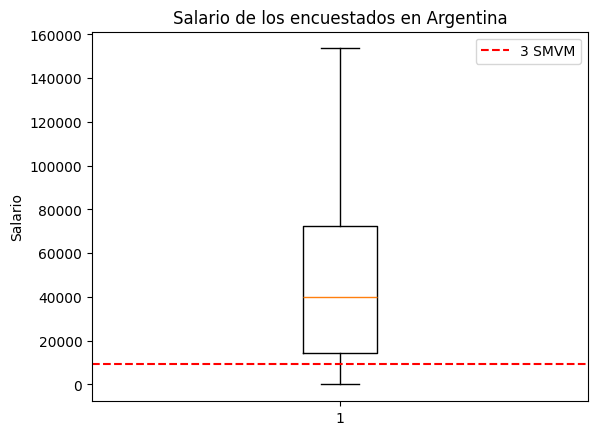

In [31]:
umbral = 3 * smvm_dolarizado
plt.boxplot(salario_encuestados_argentina)
plt.axhline(y=umbral, color="red", linestyle="--", label="3 SMVM")
plt.title("Salario de los encuestados en Argentina")
plt.ylabel("Salario")
plt.legend()
plt.show()

### 3.4.3: Resultados obtenidos y discusión

Al procesar la muestra de encuestados argentinos con ingresos declarados ($N = 160$), se obtuvo una media salarial de $46.271 USD anuales y una mediana de $40.000 USD anuales. Al contrastar estos valores frente al umbral calculado de 3 SMVM anualizados en dólares, la visualización y el análisis descriptivo evidenciaron que una abrumadora mayoría de los profesionales supera ampliamente la línea de referencia.

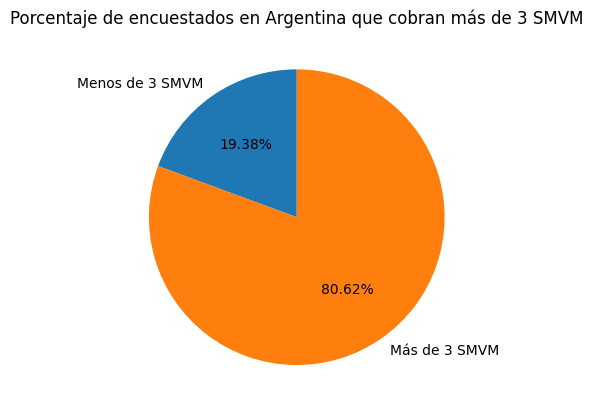

In [32]:
supera = (salario_encuestados_argentina > umbral).sum()
no_supera = (salario_encuestados_argentina <= umbral).sum()

plt.pie(
    [no_supera, supera],
    labels=["Menos de 3 SMVM", "Más de 3 SMVM"],
    autopct="%1.2f%%",
    startangle=90,
)
plt.title("Porcentaje de encuestados en Argentina que cobran más de 3 SMVM")
plt.show()

**Figura X.** Distribución de salarios anuales de los encuestados en Argentina frente al umbral de 3 Salarios Mínimos, Vitales y Móviles (SMVM).

Los resultados cuantitativos demostraron que más del 75% de los encuestados que perciben un salario en el país se ubican por encima del umbral propuesto.


### 3.5. Hipótesis 5: Experiencia Profesional y Confianza en la Precisión de la IA

#### 3.5.1: Definición y Motivación

Hipótesis a analizar:


La experiencia profesional de los desarrolladores se relaciona con el nivel de confianza que tienen en la precisión de las herramientas de Inteligencia Artificial.

Es una hipótesis bivariada (propuesta por la cátedra): una variable numérica (`WorkExp`, años de experiencia profesional) y una ordinal (`AIAcc`, confianza en la precisión de la IA en cinco niveles, de "Highly distrust" a "Highly trust").

Motivación:


Identificar si existen diferencias generacionales o profesionales en la confianza hacia la IA, aportando información útil para definir estrategias de adopción y capacitación tecnológica según los perfiles de los equipos.

Planteo estadístico:

- **H0:** la experiencia es la misma en los cinco niveles de confianza. 
- **H1:** en al menos un nivel es distinta. Nivel de significación: alfa = 0,05. Una encuesta es observacional: se evalúa **asociación**, no causalidad.

#### 3.5.2: Estrategia de abordaje y Acondicionamiento

Para validar esta hipótesis utilizaremos el Subgrupo 2 limpio (`df_impacto_ia_limpio`, ver 2.4.2), en el que los valores de experiencia iguales o superiores a 99 años ya fueron reemplazados por nulos:

Variable 1 (`WorkExp`): numérica, años de experiencia profesional. Es asimétrica, con cola larga hacia valores altos.

Variable 2 (`AIAcc`): categórica ordinal (MC) de cinco niveles.

Exclusión de variables no necesarias: las demás columnas del subgrupo (`JobSat`, `AISent`, `AISelect`, `AIThreat`, `AILearnHow`) no intervienen en esta hipótesis.

No se imputan los nulos: `AIAcc` tiene cerca de un tercio y `WorkExp` cerca de un 13%. Rellenarlos introduciría un sesgo artificial en una encuesta de opinión. El `dropna` se aplica solo sobre las dos columnas de la hipótesis y no sobre las 172 del dataset. El abordaje sigue el flujo de la práctica 6 de la cátedra: análisis gráfico, verificación de normalidad y homocedasticidad, y elección de la prueba.

In [ ]:
# Aislamos las dos variables de la hipótesis y eliminamos las filas con nulos en alguna de ellas (sin imputar)
df_hipotesis_b = df_impacto_ia_limpio[["WorkExp", "AIAcc"]].dropna().copy()

print(f"Observaciones con WorkExp y AIAcc respondidas: {len(df_hipotesis_b)} (sobre {len(df_impacto_ia_limpio)} filas)")

#### 3.5.3: Transformaciones e Ingeniería de Características

`AIAcc` es ordinal y las pruebas necesitan números. Asignamos 1 a 5 con un diccionario y `.map`. El orden se define a mano: si lo dejáramos a pandas, ordenaría alfabéticamente. `WorkExp` no se transforma: las pruebas elegidas trabajan con rangos, así que su asimetría no las invalida.

In [ ]:
orden_aiacc = {"Highly distrust": 1, "Somewhat distrust": 2, "Neither trust nor distrust": 3,
               "Somewhat trust": 4, "Highly trust": 5}

df_hipotesis_b["AIAcc_num"] = df_hipotesis_b["AIAcc"].map(orden_aiacc)

# Control: respuestas sin código (debe salir vacío)
print(df_hipotesis_b[df_hipotesis_b["AIAcc_num"].isna()]["AIAcc"].value_counts())
print(f"Total de observaciones listas para el análisis: {len(df_hipotesis_b)}")

Si el control no sale vacío, hay un texto mal escrito en el diccionario y esa categoría se estaría perdiendo.

#### 3.5.4: Modelado y Exploración Analítica

##### 3.5.4.1 Análisis gráfico

Antes de aplicar las pruebas miramos los datos. Graficamos la experiencia profesional de cada nivel de AIAcc con un boxplot con muesca (`notch=True`): la caja es el 50% central, la línea es la mediana y la muesca es una zona de incertidumbre de la mediana. Si las muescas de dos cajas no se superponen, las medianas probablemente difieren. Es una pista visual, **no una prueba**. Además, el histograma de WorkExp muestra su forma y su asimetría (`skew`).

In [ ]:
print("Personas por nivel de AIAcc:")
print(df_hipotesis_b["AIAcc_num"].value_counts().sort_index())
print("\nMediana de WorkExp por nivel de AIAcc:")
print(df_hipotesis_b.groupby("AIAcc_num")["WorkExp"].median())

plt.figure(figsize=(8, 4.5))
sns.boxplot(x="AIAcc_num", y="WorkExp", data=df_hipotesis_b, notch=True)
plt.xlabel("AIAcc (1 = desconfía mucho, 5 = confía mucho)")
plt.ylabel("Años de experiencia (WorkExp)")
plt.title("Experiencia según confianza en la precisión de la IA")
plt.show()

In [ ]:
sns.histplot(df_hipotesis_b["WorkExp"], bins=40)
plt.title("Distribución de WorkExp")
plt.show()
print("Asimetría (skew) de WorkExp:", round(df_hipotesis_b["WorkExp"].skew(), 2))

`WorkExp` presenta una asimetría positiva (cola larga hacia valores altos): muchas personas con poca experiencia y pocas con muchísima. Esto descarta los métodos que suponen normalidad (Pearson, ANOVA).

##### 3.5.4.2 Normalidad (Shapiro-Wilk, Kolmogorov-Smirnov y QQ plot)

Para elegir entre una prueba paramétrica (ANOVA) y una no paramétrica hay que ver si WorkExp es normal **dentro de cada grupo**. La H0 de normalidad dice que los datos siguen una distribución normal: si el p-valor es menor a 0,05 se rechaza. Kolmogorov-Smirnov se aplica sobre los datos estandarizados (se resta la media y se divide por el desvío). Con grupos de más de 5.000 observaciones `scipy` avisa que el p-valor de Shapiro es aproximado; es esperable.

In [ ]:
grupos_b = [g["WorkExp"] for _, g in df_hipotesis_b.groupby("AIAcc_num")]

for i, g in enumerate(grupos_b, start=1):
    estadistico, p_valor = shapiro(g)
    print(f"AIAcc = {i}: Shapiro-Wilk Estadístico={estadistico:.3f}, p-valor={p_valor:.3g}")

for i, g in enumerate(grupos_b, start=1):
    estadistico, p_valor = kstest((g - g.mean()) / g.std(), 'norm')
    print(f"AIAcc = {i}: Kolmogorov-Smirnov Estadístico={estadistico:.3f}, p-valor={p_valor:.3g}")

In [ ]:
fig, ejes = plt.subplots(1, 5, figsize=(18, 3.5))
for i, g in enumerate(grupos_b):
    stats.probplot(g, dist="norm", plot=ejes[i])
    ejes[i].set_title(f"QQ plot AIAcc = {i + 1}")
plt.tight_layout()
plt.show()

Los datos de la variable WorkExp agrupados por el nivel de AIAcc no siguen una distribución normal, una conclusión que se confirma tanto numérica como visualmente:

- Evidencia analítica (Test de Hipótesis): Las pruebas de Shapiro-Wilk y Kolmogorov-Smirnov parten de la hipótesis nula de normalidad. Al observar los resultados, todos los p-valores son infinitesimales (en el orden de e-16 a e-127). Como son estrictamente menores al nivel de significancia $\alpha = 0.05$, se rechaza categóricamente el supuesto de normalidad matemática para los cinco grupos.

- Evidencia visual (QQ Plots): Para que una variable sea considerada normal, los cuantiles empíricos (puntos azules) deben alinearse sobre la recta diagonal roja. En los gráficos, los datos forman una pronunciada curva que se despega totalmente de la línea de referencia, especialmente en los extremos. Esta curvatura (en forma de arco o "U" deformada) es el diagnóstico visual clásico de una distribución fuertemente asimétrica o sesgada, incompatible con una campana de Gauss.

##### 3.5.4.3 Homocedasticidad (Levene)

H0: las varianzas de los cinco grupos son **iguales**. Si p < 0,05 se rechaza y las varianzas son distintas.

In [ ]:
estadistico_lev, p_lev = stats.levene(*grupos_b)
print(f"Test de Levene para WorkExp: Estadístico={estadistico_lev:.3f}, p-valor={p_lev:.3g}")

alfa = 0.05
if p_lev > alfa:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("Las varianzas de WorkExp son iguales entre los grupos de AIAcc.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Las varianzas de WorkExp son diferentes entre los grupos de AIAcc.")

##### 3.5.4.4 Prueba de hipótesis: Kruskal-Wallis

Hay **cinco grupos independientes** (cada persona está en un solo nivel de AIAcc) y WorkExp no es normal. Por eso usamos **Kruskal-Wallis**, la alternativa no paramétrica al ANOVA para comparar más de dos grupos. Es la generalización de Mann-Whitney U (que compara solo dos). Solo indica **si hay diferencia** en algún grupo, no entre cuáles ni en qué sentido.

- **H0:** WorkExp tiene la misma distribución en los cinco niveles de AIAcc.
- **H1:** en al menos un nivel es distinta. Nivel de significación: alfa = 0,05.

In [ ]:
estadistico_kw, p_kw = stats.kruskal(*grupos_b)
print(f"Test de Kruskal-Wallis para WorkExp: Estadístico={estadistico_kw:.3f}, p-valor={p_kw:.3g}")

alfa = 0.05
if p_kw > alfa:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en WorkExp entre los niveles de AIAcc.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en WorkExp entre los niveles de AIAcc.")

##### 3.5.4.5 Sentido de la asociación: correlación de Spearman

Kruskal-Wallis no dice en qué sentido va la relación. Para eso calculamos la correlación de Spearman entre WorkExp y AIAcc_num. Trabaja con rangos (el orden de los valores), por lo que sirve para una variable ordinal y no exige normalidad. Va de -1 a 1: positiva significa que a más experiencia le corresponde más confianza, y negativa que le corresponde menos; cercana a 0 significa que no hay asociación.

In [ ]:
tabla_corr = df_hipotesis_b[["WorkExp", "AIAcc_num"]].corr(method="spearman")
rho = tabla_corr.loc["WorkExp", "AIAcc_num"]
print(tabla_corr)
print(f"\nCorrelación de Spearman = {rho:.3f}")

#### 3.5.5: Resultados obtenidos y discusión

##### 3.5.5.1 Hipótesis rechazada


Rechazamos formalmente H0.

La prueba de Kruskal-Wallis arrojó un estadístico H de 38,68 (4 grados de libertad) y un p-valor de 8,1e-8, inferior al nivel de significación de 0,05. Esto indica que existen diferencias estadísticamente significativas en los años de experiencia entre los distintos niveles de confianza hacia la IA. La correlación de Spearman fue negativa (rho = -0,034): una mayor confianza en la precisión de estas herramientas se asocia con una experiencia profesional ligeramente menor.

##### 3.5.5.2 Discusión de resultados


La experiencia media disminuye de forma progresiva desde 14,55 años entre quienes desconfían mucho hasta 13,07 años entre quienes confían mucho (14,18, 14,08 y 13,57 en los niveles intermedios). Las medianas son 12, 12, 11, 11 y 10 años. Todos los supuestos se verificaron: Shapiro-Wilk rechazó la normalidad en los cinco grupos (p menor a 1e-25) y Levene rechazó la igualdad de varianzas (p = 1,1e-4), lo que justifica una prueba no paramétrica.

In [ ]:
medias_b = df_hipotesis_b.groupby("AIAcc_num")["WorkExp"].mean()

plt.figure(figsize=(7, 4))
plt.plot(medias_b.index, medias_b.values, marker="o")
for nivel, valor in medias_b.items():
    plt.annotate(f"{valor:.2f}", (nivel, valor), textcoords="offset points", xytext=(0, 8), ha="center")
plt.xticks([1, 2, 3, 4, 5])
plt.xlabel("AIAcc (1 = desconfía mucho, 5 = confía mucho)")
plt.ylabel("Media de WorkExp en años (eje recortado)")
plt.title("Experiencia media según confianza en la precisión de la IA")
plt.grid(True, alpha=0.3)
plt.show()

Aunque la media baja de forma ordenada, el gráfico tiene el eje vertical recortado para que se aprecie la tendencia: la diferencia entre los extremos es de apenas 1,5 años (2 años en la mediana), y rho = -0,034 indica una asociación prácticamente nula (rho al cuadrado es cercano a 0,001, es decir, la confianza en la IA comparte aproximadamente un 0,1% de la variación en los rangos de experiencia). Con 30.765 observaciones, una diferencia pequeña alcanza un p-valor mínimo: la relación es estadísticamente significativa pero de relevancia práctica muy limitada. El grupo "Highly trust" tiene solo 923 personas frente a entre 5.991 y 9.141 en los demás, así que las comparaciones que lo incluyen son menos precisas. Kruskal-Wallis no indica entre qué niveles se da la diferencia.

Limitaciones: el análisis cubre 30.765 de 49.191 respuestas (`AIAcc` y `WorkExp` tienen nulos que no se imputaron y los valores de 99 años o más se pasaron a nulo); `AIAcc` se codificó sin asumir niveles equidistantes; `WorkExp` es autodeclarada; la muestra es voluntaria y online; y una asociación no implica causalidad.

##### 3.5.5.3 Conclusión de negocio


Los desarrolladores con más experiencia tienden a confiar algo menos en la precisión de la IA que los más nuevos, pero la diferencia es muy pequeña (alrededor de 1,5 años entre los extremos). Para una organización, la antigüedad **no es un buen criterio** para decidir cómo capacitar o introducir herramientas de IA: la confianza es parecida a lo largo de todos los niveles de experiencia. Una posible explicación, que los datos no permiten confirmar, es que quienes llevan más años en la profesión tienen más elementos para detectar errores en los resultados de la IA.

### 3.6. Hipótesis 6: Satisfacción y Cambio de Rol

#### 3.6.1. Definición y Motivación

Hipotesis a analizar:
¿Están los distintos niveles de satisfacción en los distintos aspectos del trabajo actual relacionados a la consideración de un cambio de rol o de carrera?

Motivacion:
Para los departamentos de Recursos Humanos, anticipar la fuga de talento es un desafío crítico. Evaluar si las clásicas "encuestas de satisfacción" (clima laboral, beneficios, autonomía) tienen un poder predictivo real sobre la renuncia o el cambio de carrera permite optimizar las estrategias de retención.

#### 3.6.2. Estrategia de Abordaje y Limpieza Modular

Para validar esta hipótesis multivariada, partiremos del Subgrupo 3 (Satisfacción, Retención y Criterio Tecnológico), el cual ya fue saneado de encuestas incompletas en la etapa de limpieza general (ver 2.4.3). Nuestro paso de acondicionamiento será aislar las variables estrictamente necesarias para este cruce y eliminar los valores nulos residuales de nuestra variable dependiente:

Variable Objetivo (NewRole): Columna categórica (MC) que captura la progresión de intenciones del desarrollador respecto a un cambio laboral en el último año. Se descartarán definitivamente aquellos encuestados que no hayan respondido a esta pregunta, ya que es el vector objetivo (y) indispensable para los modelos de clasificación.

Variables Predictoras (JobSatPoints_1 a 15): 15 columnas numéricas ordinales (RO) donde el valor 1 indica la máxima prioridad de satisfacción y el 15 la mínima.

Exclusión de variables incompatibles/redundantes: Filtraremos intencionalmente la opción de texto libre (JobSatPoints_15_TEXT) por no ser procesable matemáticamente para los algoritmos de reducción de dimensionalidad. Asimismo, excluiremos la métrica de satisfacción global (JobSat) para enfocarnos exclusivamente en los distintos aspectos del trabajo, tal como lo exige el enunciado.

Filtrado de las columnas necesarias:

In [ ]:
cols_sat_float = [
    col for col in df_subgrupo_satisfaccion_limpio.columns 
    if col.startswith('JobSatPoints') and not col.endswith('TEXT')
]

cols_hipotesis_c_utiles = cols_sat_float + ['NewRole']

df_hipotesis_c = df_subgrupo_satisfaccion_limpio[cols_hipotesis_c_utiles].dropna(subset=['NewRole']).copy()

print(f"Total de observaciones listas para el análisis multivariado: {len(df_hipotesis_c)}")


#### 3.6.3. Ingeniería de Características (Discretización e Inversión)

##### 3.6.3.1 Variable objetivo

Análisis de la Variable Objetivo (NewRole)

Antes de aplicar la reducción de dimensionalidad, analizamos la distribución de nuestra variable objetivo. 

In [ ]:
df_hipotesis_c["NewRole"].value_counts()

Como se observa, se trata de una variable cualitativa nominal. Si bien las tres primeras opciones sugieren un orden de intención (nula, leve, fuerte), las dos últimas representan acciones concretas y contextuales (cambio voluntario vs. involuntario) que rompen cualquier jerarquía matemática. Por lo tanto, el análisis la tratará como 5 categorías discretas e independientes.

##### 3.6.3.2 Variables predictoras

Variables Predictoras:

Las variables predictoras JobSatPoints presentan un ranking ordinal de 1 a 15, donde 1 representa la máxima prioridad. Para optimizar el rendimiento de los algoritmos de reducción de dimensionalidad (basados en varianza y distancias), aplicaremos una transformación sobre estas columnas fundamentada en dos objetivos:

Reducción de ruido (Binning): Las diferencias minúsculas entre puestos bajos (ej. rankear un atributo en el puesto 13 vs 14) aportan ruido aleatorio en lugar de patrones reales. Agruparemos las respuestas para consolidar la intención del usuario.

Inversión de magnitud: Para que los algoritmos asocien correctamente una mayor intensidad con una mayor importancia matemática, invertiremos la escala original.

Aplicaremos una discretización de 5 niveles jerárquicos:

5 (Muy importante): Puestos 1, 2 y 3

4 (Importante): Puestos 4, 5 y 6

3 (Neutral): Puestos 7, 8 y 9

2 (No tan importante): Puestos 10, 11 y 12

1 (No importante): Puestos 13, 14 y 15

Cabe destacar que, durante la fase exploratoria, se evaluaron empíricamente otras estrategias de agrupamiento (como la condensación en 3 niveles de prioridad o el procesamiento de los rankings en crudo sin transformación). Sin embargo, ninguna de estas alternativas logró mejoras estadísticamente significativas en las métricas de varianza acumulada, reafirmando la decisión de aplicar un esquema de 5 intervalos para balancear la reducción de ruido y la retención de granularidad.

Transformacion sobre variables predictoras:

In [ ]:
bins = [0, 3, 6, 9, 12, 15] 
labels = [5, 4, 3, 2, 1]    

for col in cols_sat_float:
    df_hipotesis_c[col] = pd.cut(df_hipotesis_c[col], bins=bins, labels=labels, right=True)
    df_hipotesis_c[col] = pd.to_numeric(df_hipotesis_c[col])


#### 3.6.4. Escalado y Exploración Multivariada (PCA y UMAP)

##### 3.6.4.1 Estandarizacion

Aunque la discretización previa unificó las 15 variables predictoras bajo una misma amplitud (de 1 a 5), la estandarización (Z-score) sigue siendo un requerimiento matemático estricto antes de aplicar algoritmos basados en la maximización de varianzas y el cálculo de distancias geométricas, como PCA y UMAP. Este proceso centra los datos restándole a cada observación la media de su columna y dividiéndola por su desvío estándar, forzando a que todas las variables tengan una media de 0 y una varianza de 1. De esta forma, se establece una escala uniforme que impide que variables con magnitudes o dispersiones naturalmente mayores dominen el modelo y sesguen el cálculo de la varianza.

Para implementarlo, separaremos la matriz de características (X) de la variable objetivo categórica (y) y aplicaremos la transformación.

In [ ]:
from sklearn.preprocessing import StandardScaler

cols_predictoras = [col for col in df_hipotesis_c.columns if col != 'NewRole']
X = df_hipotesis_c[cols_predictoras]
y = df_hipotesis_c['NewRole']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Dimensiones de la matriz escalada (X_scaled): {X_scaled.shape}")

##### 3.6.4.2 Analisis de Componentes Principales (PCA)

Con los datos estandarizados, aplicaremos Análisis de Componentes Principales (PCA) para reducir la dimensionalidad de las 15 variables de satisfacción a un espacio bidimensional (2 componentes). Nuestro objetivo es evaluar visual y cuantitativamente si existe una separación lineal natural entre los usuarios según su postura frente a un cambio de rol.

Se proyectarán los datos en un gráfico de dispersión, utilizando transparencia para identificar densidades (mitigando el overplotting) y se extraerá el porcentaje de varianza explicada de cada componente para validar matemáticamente la representatividad de la proyección.

In [ ]:
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Calculamos el PCA sobre los datos escalados
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Extraemos la varianza para los ejes
var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100

# 2. Hacemos la figura más ancha de entrada
plt.figure(figsize=(12, 8))

# 3. Graficamos con Seaborn
sns.scatterplot(
    x=X_pca[:, 0], 
    y=X_pca[:, 1],
    hue=df_hipotesis_c['NewRole'], 
    palette='Set1',
    alpha=0.5,
    s=30
)

plt.grid(True, alpha=0.3)
plt.xlabel(f'Proyección PCA 1 ({var_pc1:.2f}% varianza)')
plt.ylabel(f'Proyección PCA 2 ({var_pc2:.2f}% varianza)')
plt.title('Proyección PCA: Satisfacción Laboral vs Cambio de Rol')

# 4. Posicionamos la leyenda afuera y ajustamos el margen derecho al 75%
plt.legend(title='NewRole', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.subplots_adjust(right=0.75) 

plt.show()

# Imprimimos el total para la conclusión del informe
print(f"Varianza total explicada en 2D: {(var_pc1 + var_pc2):.2f}%")

Justificación Cuantitativa: Varianza Acumulada

La visualización anterior presenta una fuerte superposición de las categorías. Para fundamentar si esto se debe a la ausencia real de patrones o a una limitación del espacio bidimensional, analizaremos la proporción explicada al escalar hasta 5 componentes principales. Según los criterios teóricos, buscamos retener idealmente más del 80% de la varianza total del dataset original para considerar la representación lineal como robusta.

In [ ]:
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# 1. Calculamos PCA para 5 componentes sobre los datos escalados
pca_5 = PCA(n_components=5)
pca_5.fit(X_scaled)

# 2. Extraemos la varianza individual y calculamos la acumulada
var_individual = pca_5.explained_variance_ratio_ * 100
var_acumulada = np.cumsum(var_individual)
componentes = np.arange(1, 6)

# 3. Graficamos la integración (Barras para individual, Línea para acumulada)
plt.figure(figsize=(9, 5))
plt.bar(componentes, var_individual, alpha=0.6, color='#4C72B0', label='Varianza Individual')
plt.plot(componentes, var_acumulada, marker='o', color='#C44E52', linewidth=2, label='Varianza Acumulada')

# Agregamos las etiquetas de texto sobre la línea acumulada
for i, txt in enumerate(var_acumulada):
    plt.annotate(f'{txt:.1f}%', (componentes[i], var_acumulada[i] + 1.5), ha='center', fontweight='bold')

plt.xlabel('Número de Componente Principal')
plt.ylabel('Porcentaje de Varianza Explicada (%)')
plt.title('Varianza Explicada Individual y Acumulada (Top 5 Componentes)')
plt.xticks(componentes)
plt.ylim(0, max(var_acumulada) + 10)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

Conclusión del Análisis de Componentes Principales (PCA)

La proyección obtenida demuestra gráficamente que no existe una relación lineal simple que logre separar a los encuestados según su intención de cambio de rol. Las distintas categorías de NewRole se distribuyen de manera homogénea y superpuesta (overplotting) a lo largo de todo el plano, sin formar clústeres aislados.

Este comportamiento está fundamentado matemáticamente en la baja varianza explicada. Las dos primeras componentes retienen una porción mínima de la información original de la encuesta. Asimismo, el gráfico de varianza acumulada evidencia que incorporar una tercera, cuarta o quinta componente aporta mejoras puramente marginales, manteniéndonos muy lejos del umbral necesario (>80%) para justificar una representación lineal de los datos.   

Dado que PCA asume relaciones estrictamente lineales en subespacios planos, el modelo no logra representar relaciones complejas entre las características. Al agotar la capacidad de estas transformaciones lineales, pasaremos a explorar la topología de los datos mediante técnicas de reducción no lineal para descartar definitivamente cualquier patrón oculto.   

##### 3.6.4.3 Reduccion de Dimensionalidad No Lineal (UMAP)

Reducción de Dimensionalidad No Lineal (UMAP)

Dado que PCA arrojó una baja varianza explicada y no logró separar las clases linealmente, aplicaremos UMAP (Uniform Manifold Approximation and Projection). 

Este algoritmo de manifold learning nos permitirá buscar patrones geométricos complejos y estructuras no lineales subyacentes en las prioridades de satisfacción laboral, proyectándolas nuevamente a 2 dimensiones para evaluar si se forman agrupaciones según la intención de cambio de rol de los desarrolladores.

In [ ]:
from umap import UMAP
import seaborn as sns
import matplotlib.pyplot as plt

reductor_umap = UMAP(n_components=2, random_state=42)
X_umap = reductor_umap.fit_transform(X_scaled)

print(f'Dimensiones antes de UMAP: {X_scaled.shape}')
print(f'Dimensiones después de UMAP: {X_umap.shape}')

plt.figure(figsize=(12, 8))

sns.scatterplot(
    x=X_umap[:, 0], 
    y=X_umap[:, 1], 
    hue=df_hipotesis_c["NewRole"], 
    palette='Set1',
    alpha=0.5,
    s=20 
)

plt.grid(True, alpha=0.3)
plt.xlabel('Componente 1 UMAP')
plt.ylabel('Componente 2 UMAP')
plt.title('Representación no lineal con UMAP: Satisfacción vs Cambio de Rol')

plt.legend(title='NewRole', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.subplots_adjust(right=0.75) 

plt.show()

Conclusión del Análisis de Reducción No Lineal (UMAP):

Al observar la proyección no lineal, se destacan dos conclusiones fundamentales:

Descubrimiento de subestructuras (Similitud Local): UMAP logró identificar agrupaciones aisladas ("islas") fuera de la nube principal de datos. Esto indica la existencia de una minoría de encuestados que comparten un perfil de satisfacción altamente específico y similar entre sí, distanciado del patrón de respuestas de la mayoría.  


Independencia de la variable objetivo (NewRole): Al analizar la distribución de la variable categórica en el gráfico, observamos que las clases siguen estando mezcladas de forma heterogénea en la nube principal. Más importante aún, incluso dentro del clúster aislado (la "isla"), conviven usuarios con decisiones de carrera diametralmente opuestas (los 5 colores se encuentran presentes).

Estos resultados nos permiten descartar que la superposición observada en PCA se debiera exclusivamente a la presencia de estructuras complejas no lineales en el espacio de alta dimensión.

##### 3.6.4.4 Regresion Logistica Multinomial

Validación Predictiva mediante Regresión Logística Multinomial

Si bien las técnicas de reducción de dimensionalidad (PCA y UMAP) demostraron visualmente la ausencia de clústeres separables, procederemos a validar esta conclusión de manera cuantitativa utilizando un modelo de Machine Learning de clasificación supervisada.

Implementaremos una Regresión Logística Multinomial utilizando las 15 variables de satisfacción como predictoras. Nuestro objetivo es evaluar si el algoritmo es capaz de aprender algún patrón matemático subyacente que le permita predecir correctamente la categoría de NewRole a la que pertenece un desarrollador. Si, como sugieren los gráficos anteriores, no existe correlación entre las prioridades y la decisión de cambio, el modelo arrojará un Accuracy (Exactitud) deficiente, confirmando el rechazo de la hipótesis de forma irrefutable.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

modelo_logistico = LogisticRegression(max_iter=1000, random_state=42)
modelo_logistico.fit(X_train, y_train)

y_pred = modelo_logistico.predict(X_test)

exactitud = accuracy_score(y_test, y_pred)
matriz_conf = confusion_matrix(y_test, y_pred)

print(f"Exactitud (Accuracy) del modelo: {exactitud:.4f} ({exactitud*100:.2f}%)")

mapeo_clases_cortas = {
    'I have neither consider or transitioned into a new career or industry': 'Nula intención / Sin cambios',
    'I have somewhat considered changing my career and/or the industry I work in': 'Leve consideración',
    'I have strongly considered changing my career and/or the industry I work in': 'Fuerte consideración',
    'I have transitioned into a new career and/or industry voluntarily': 'Transición (Voluntaria)',
    'I have transitioned into a new career and/or industry involuntarily': 'Transición (Involuntaria)'
}

etiquetas_cortas = [mapeo_clases_cortas[clase] for clase in modelo_logistico.classes_]

plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz_conf, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=etiquetas_cortas,
    yticklabels=etiquetas_cortas
)

plt.title('Matriz de Confusión: Predicción de Cambio de Rol')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#### 3.6.5. Resultados obtenidos y discusión

##### 3.6.5.1 Rechazo de hipotesis

Hipótesis rechazada:

Rechazamos formalmente la Hipótesis C. La premisa inicial suponía que las prioridades que un desarrollador le asigna a distintos factores de su trabajo actual (salario, autonomía, equipo, etc.) poseían poder predictivo sobre su decisión de cambiar de carrera o rol. Sin embargo, tras validar la ausencia de patrones en PCA y UMAP, el modelo de Regresión Logística Multinomial colapsó estructuralmente. Arrojó una exactitud (Accuracy) del 46.34%, un valor que coincide de forma exacta con la proporción de la clase mayoritaria ("Nula intención / Sin cambios", con 11.460 sobre 24.729 encuestados). Esto demuestra matemáticamente que, ante la falta de un patrón real, el algoritmo optó por una heurística ingenua (predecir a todos en la clase mayoritaria), confirmando que las 15 variables de satisfacción carecen de capacidad predictiva para anticipar un cambio laboral.

##### 3.6.5.2 Discusion de resultados

¿Por qué podría pasar esto en el mercado real?

La brecha entre la "Opinión" y la "Acción": Este fenómeno contraintuitivo se explica por la diferencia entre estar insatisfecho y poder hacer algo al respecto. Un desarrollador puede rankear el "Salario" como su máxima prioridad y estar muy descontento con él, pero la acción concreta de transicionar de rol requiere un costo de energía alto, tiempo libre para hacer entrevistas técnicas y tolerancia al riesgo. La insatisfacción genera la queja, pero no garantiza la renuncia inmediata.

Variables Omitidas (Contexto Macroeconómico y Demográfico): Como no se incluyeron en este cruce variables externas, el modelo fracasó. La decisión de cambiar de trabajo en la industria tecnológica está hoy fuertemente impulsada por factores externos: la edad del encuestado, sus cargas familiares, o el estado macroeconómico global (como las recientes olas de despidos masivos o layoffs en el sector Tech), las cuales congelan la movilidad laboral independientemente de qué tan prioritaria sea la autonomía o el liderazgo para el empleado.

##### 3.6.5.3 Conclusion de negocio

Conclusión de negocio: Rechazamos la hipótesis porque anticipar la fuga de talento requiere ir mucho más allá del "clima laboral". Para los departamentos de Recursos Humanos, este modelo demuestra que las tradicionales "encuestas de satisfacción internas" son insuficientes para predecir renuncias. Retener talento exige monitorear el contexto económico, el seniority y las oportunidades reales que ese empleado tiene en el mercado externo, no solo ordenando qué le molesta de su oficina actual.